# Práctica: Comparación de modelos de regresión

**Materia:** Tópicos de Big Data
**Tema:** Introducción al aprendizaje supervisado mediante modelos de regresión
**Herramientas:** Python · Jupyter Notebook · Pandas · NumPy · Matplotlib · Scikit-learn

---

## 1. Objetivo

Construir diferentes modelos de aprendizaje supervisado para realizar **proyecciones del número de nacimientos y defunciones** de un país, utilizando datos históricos.

Durante la práctica se implementarán y compararán visualmente tres modelos:

1. Regresión lineal
2. Regresión polinomial
3. Random Forest Regressor

Al finalizar, podrás observar cómo **diferentes modelos generan predicciones diferentes utilizando exactamente los mismos datos**.

> **Nota:** En esta práctica **no** se realizará todavía la evaluación formal de los modelos. La evaluación mediante métricas se realizará en la siguiente sesión.

---

## 2. Dataset

Utilizaremos información de **Our World in Data (OWID)** sobre nacimientos y defunciones, que incluye datos históricos y proyecciones hasta el año 2100.

Fuente: *Our World in Data – Births and deaths projected to 2100* (basado en las estimaciones y proyecciones de la ONU).

El dataset contiene información por **país (o región) y año**.

# PARTE 1. Importar las bibliotecas

En esta práctica utilizaremos:

* **Pandas** para trabajar con el dataset.
* **NumPy** para trabajar con arreglos y preparar datos.
* **Matplotlib** para visualizar los datos y las predicciones.
* **Scikit-learn** para construir los modelos de Machine Learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import RandomForestRegressor

# PARTE 2. Cargar el dataset

## 3. Cargar los datos

Leemos el archivo CSV directamente desde la página de OWID.

> **Si no hay internet (o la descarga falla):** descarga el CSV desde la URL de la celda siguiente, guárdalo en la misma carpeta que este notebook con el nombre `births-and-deaths-projected-to-2100.csv` y vuelve a ejecutar la celda. El código lo detecta automáticamente.

In [3]:
url = "https://ourworldindata.org/grapher/births-and-deaths-projected-to-2100.csv?v=1&csvType=full&useColumnShortNames=true"

try:
    df = pd.read_csv(
        url,
        storage_options={
            "User-Agent": "Our World In Data data fetch/1.0"
        }
    )
except Exception as error:
    print("No fue posible descargar el archivo desde internet:", error)
    print("Se utilizará el archivo local 'births-and-deaths-projected-to-2100.csv'")
    df = pd.read_csv("births-and-deaths-projected-to-2100.csv")

df.head()

,entity,code,year,deaths__sex_all__age_all__variant_estimates,deaths__sex_all__age_all__variant_medium__projected,births__sex_all__age_all__variant_estimates,births__sex_all__age_all__variant_medium__projected
0,Afghanistan,AFG,1950,290972.0,NaN,383985.0,NaN
1,Afghanistan,AFG,1951,288752.0,NaN,391002.0,NaN
2,Afghanistan,AFG,1952,288059.0,NaN,397663.0,NaN
3,Afghanistan,AFG,1953,287712.0,NaN,404666.0,NaN
4,Afghanistan,AFG,1954,289189.0,NaN,410428.0,NaN


## 4. Explorar el dataset

Observemos la estructura del `DataFrame`.

In [4]:
print("Dimensiones (filas, columnas):", df.shape)
print()
print("Columnas:")
for columna in df.columns:
    print("  -", columna)

Dimensiones (filas, columnas): (39562, 7)

Columnas:
  - entity
  - code
  - year
  - deaths__sex_all__age_all__variant_estimates
  - deaths__sex_all__age_all__variant_medium__projected
  - births__sex_all__age_all__variant_estimates
  - births__sex_all__age_all__variant_medium__projected


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 39562 entries, 0 to 39561
Data columns (total 7 columns):
 #   Column                                               Non-Null Count  Dtype  
---  ------                                               --------------  -----  
 0   entity                                               39562 non-null  str    
 1   code                                                 38354 non-null  str    
 2   year                                                 39562 non-null  int64  
 3   deaths__sex_all__age_all__variant_estimates          18944 non-null  float64
 4   deaths__sex_all__age_all__variant_medium__projected  19712 non-null  float64
 5   births__sex_all__age_all__variant_estimates          19166 non-null  float64
 6   births__sex_all__age_all__variant_medium__projected  19943 non-null  float64
dtypes: float64(4), int64(1), str(2)
memory usage: 2.1 MB


In [6]:
df.head(10)

,entity,code,year,deaths__sex_all__age_all__variant_estimates,deaths__sex_all__age_all__variant_medium__projected,births__sex_all__age_all__variant_estimates,births__sex_all__age_all__variant_medium__projected
0,Afghanistan,AFG,1950,290972.0,NaN,383985.0,NaN
1,Afghanistan,AFG,1951,288752.0,NaN,391002.0,NaN
2,Afghanistan,AFG,1952,288059.0,NaN,397663.0,NaN
3,Afghanistan,AFG,1953,287712.0,NaN,404666.0,NaN
4,Afghanistan,AFG,1954,289189.0,NaN,410428.0,NaN
5,Afghanistan,AFG,1955,286725.0,NaN,417650.0,NaN
6,Afghanistan,AFG,1956,286654.0,NaN,425071.0,NaN
7,Afghanistan,AFG,1957,286114.0,NaN,432044.0,NaN
8,Afghanistan,AFG,1958,285911.0,NaN,439867.0,NaN
9,Afghanistan,AFG,1959,285500.0,NaN,447510.0,NaN


Revisemos las entidades disponibles:

In [7]:
print("Número de entidades:", df["entity"].nunique())
df["entity"].unique()

Número de entidades: 262


<StringArray>
[      'Afghanistan',            'Africa',       'Africa (UN)',
           'Albania',           'Algeria',    'American Samoa',
     'Americas (UN)',           'Andorra',            'Angola',
          'Anguilla',
 ...
           'Vanuatu',           'Vatican',         'Venezuela',
           'Vietnam', 'Wallis and Futuna',    'Western Sahara',
             'World',             'Yemen',            'Zambia',
          'Zimbabwe']
Length: 262, dtype: str

### Pregunta

**¿Cuál es la unidad de observación de cada fila del dataset?**

*Respuesta:* Cada fila es un **par entidad-año**: un país o región (`entity`) en un año específico (`year`). Es decir, la fila "Mexico, 1990" contiene los nacimientos y defunciones de México en ese año. Por eso el dataset tiene 39,562 filas: 262 entidades por el rango de años disponible (1950-2100).


## 5. Preparar los nombres de las columnas

Al explorar el dataset notamos dos cosas:

1. Los nombres de las columnas son largos y difíciles de escribir.
2. Los **datos históricos** (`..._variant_estimates`) y las **proyecciones de la ONU** (`..._variant_medium__projected`) vienen en **columnas separadas**. Cuando una fila es histórica, la columna de proyección está vacía (`NaN`), y viceversa.

Vamos a renombrar las columnas y a crear dos columnas unificadas, `births` y `deaths`, que contengan el dato histórico cuando existe y la proyección de OWID cuando no.

In [8]:
df = df.rename(columns={
    "entity": "Entity",
    "code": "Code",
    "year": "Year",
    "births__sex_all__age_all__variant_estimates": "births_estimates",
    "births__sex_all__age_all__variant_medium__projected": "births_projected",
    "deaths__sex_all__age_all__variant_estimates": "deaths_estimates",
    "deaths__sex_all__age_all__variant_medium__projected": "deaths_projected",
})


df.head()

,Entity,Code,Year,deaths_estimates,deaths_projected,births_estimates,births_projected
0,Afghanistan,AFG,1950,290972.0,NaN,383985.0,NaN
1,Afghanistan,AFG,1951,288752.0,NaN,391002.0,NaN
2,Afghanistan,AFG,1952,288059.0,NaN,397663.0,NaN
3,Afghanistan,AFG,1953,287712.0,NaN,404666.0,NaN
4,Afghanistan,AFG,1954,289189.0,NaN,410428.0,NaN


In [9]:
df_inicial = df.copy()
df_inicial.head(3)

,Entity,Code,Year,deaths_estimates,deaths_projected,births_estimates,births_projected
0,Afghanistan,AFG,1950,290972.0,NaN,383985.0,NaN
1,Afghanistan,AFG,1951,288752.0,NaN,391002.0,NaN
2,Afghanistan,AFG,1952,288059.0,NaN,397663.0,NaN


In [10]:
# Columna unificada: dato histórico si existe; si no, la proyección de OWID
df["births"] = df["births_estimates"].fillna(df["births_projected"])
df["deaths"] = df["deaths_estimates"].fillna(df["deaths_projected"])
df.head()

,Entity,Code,Year,deaths_estimates,deaths_projected,births_estimates,births_projected,births,deaths
0,Afghanistan,AFG,1950,290972.0,NaN,383985.0,NaN,383985.0,290972.0
1,Afghanistan,AFG,1951,288752.0,NaN,391002.0,NaN,391002.0,288752.0
2,Afghanistan,AFG,1952,288059.0,NaN,397663.0,NaN,397663.0,288059.0
3,Afghanistan,AFG,1953,287712.0,NaN,404666.0,NaN,404666.0,287712.0
4,Afghanistan,AFG,1954,289189.0,NaN,410428.0,NaN,410428.0,289189.0


# PARTE 3. Seleccionar un país

## 6. Seleccionar México

Para esta práctica utilizaremos México.

In [11]:
pais = "Mexico"

df_mexico = df[df["Entity"] == pais]

df_mexico.head()

,Entity,Code,Year,deaths_estimates,deaths_projected,births_estimates,births_projected,births,deaths
22801,Mexico,MEX,1950,596771.0,NaN,1358501.0,NaN,1358501.0,596771.0
22802,Mexico,MEX,1951,588791.0,NaN,1392106.0,NaN,1392106.0,588791.0
22803,Mexico,MEX,1952,582415.0,NaN,1423352.0,NaN,1423352.0,582415.0
22804,Mexico,MEX,1953,565876.0,NaN,1454762.0,NaN,1454762.0,565876.0
22805,Mexico,MEX,1954,552321.0,NaN,1488719.0,NaN,1488719.0,552321.0


In [12]:
print("Rango de años:", df_mexico["Year"].min(), "-", df_mexico["Year"].max())
print("Número de filas:", df_mexico.shape[0])

Rango de años: 1950 - 2100
Número de filas: 151


## 7. Revisar las variables disponibles

Identifica las columnas correspondientes a: **año**, **nacimientos** y **defunciones**.

In [13]:
df_mexico.columns

Index(['Entity', 'Code', 'Year', 'deaths_estimates', 'deaths_projected',
       'births_estimates', 'births_projected', 'births', 'deaths'],
      dtype='str')

Para esta práctica utilizaremos:

```text
Year
births
deaths
```

# PARTE 4. Explorar visualmente los datos

## 8. Nacimientos a través del tiempo

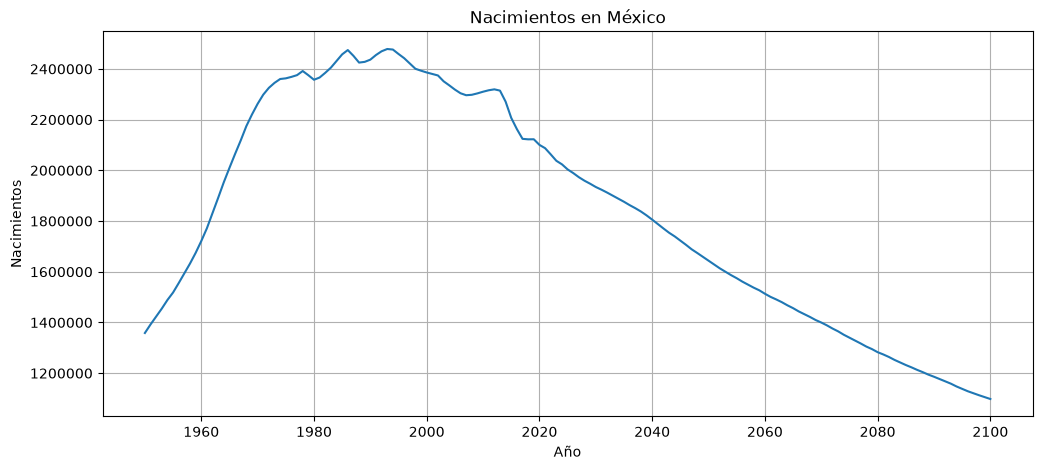

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_mexico["Year"],
    df_mexico["births"]
)

plt.title("Nacimientos en México")
plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.grid()
plt.show()

## 9. Defunciones a través del tiempo

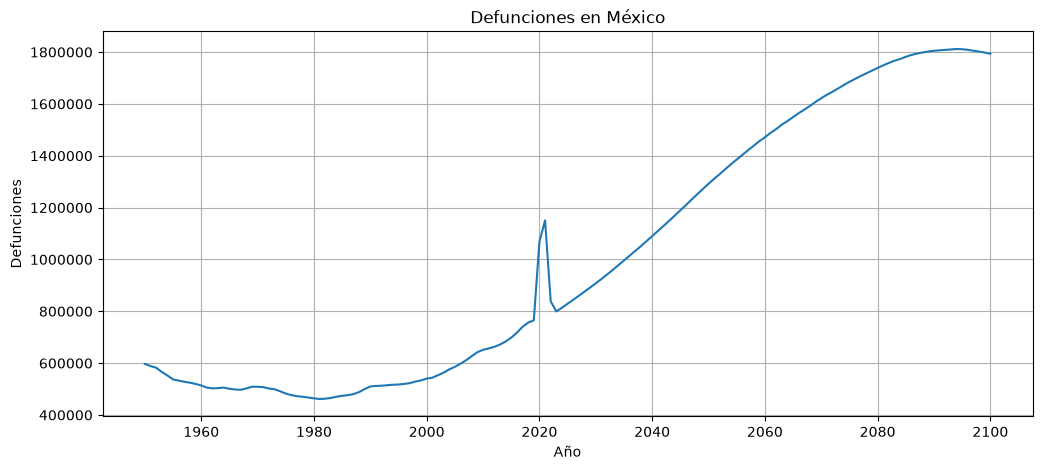

In [15]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_mexico["Year"],
    df_mexico["deaths"]
)

plt.title("Defunciones en México")
plt.xlabel("Año")
plt.ylabel("Defunciones")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.grid()
plt.show()

### Preguntas de observación

1. ¿Los nacimientos presentan una tendencia constante?
2. ¿Las defunciones presentan una tendencia constante?
3. ¿Las dos variables parecen seguir el mismo comportamiento?
4. ¿Observas cambios en la tendencia a través del tiempo?

*Observaciones:*

1. **No.** Los nacimientos suben desde 1950 (1.36 millones) hasta un máximo cerca de 1993 (2.48 millones) y a partir de ahí bajan de forma sostenida. La serie tiene claramente dos etapas, no una sola tendencia.
2. **Tampoco.** Las defunciones crecen lentamente casi toda la serie, con un pico muy marcado en 2020-2021 (1.15 millones en 2021) por la pandemia de COVID-19, y después regresan a alrededor de 800 mil. Hacia el futuro la proyección las hace crecer con fuerza.
3. **No.** Van en direcciones opuestas en las últimas décadas: los nacimientos bajan mientras las defunciones suben. Esto es el patrón típico de la transición demográfica (menos fecundidad y población envejeciendo).
4. **Sí, y son evidentes.** El quiebre de los nacimientos alrededor de 1993 y el pico de defunciones en 2020-2021 son los dos cambios más notorios. Esto ya anticipa que un modelo con una sola recta va a tener problemas para representar la serie completa.


# PARTE 5. Separar datos históricos y proyectados

## 10. Identificar el punto de separación

El dataset contiene **datos históricos** y **proyecciones**. Antes de separarlos, verifiquemos dónde termina uno y empieza el otro:

In [16]:
ultimo_historico = df_mexico.loc[df_mexico["births_estimates"].notna(), "Year"].max()
primera_proyeccion = df_mexico.loc[df_mexico["births_projected"].notna(), "Year"].min()

print("Último año con dato histórico:", ultimo_historico)
print("Primer año con proyección de OWID:", primera_proyeccion)

Último año con dato histórico: 2023
Primer año con proyección de OWID: 2024


Para esta práctica utilizaremos como punto de separación el **año 2023**. Creamos dos `DataFrames`:

In [17]:
df_historico = df_mexico[
    df_mexico["Year"] <= 2023
]

df_proyectado = df_mexico[
    df_mexico["Year"] > 2023
]

print(df_historico.head(3))
print(df_proyectado.head(3))

       Entity Code  Year  deaths_estimates  deaths_projected  \
22801  Mexico  MEX  1950          596771.0               NaN   
22802  Mexico  MEX  1951          588791.0               NaN   
22803  Mexico  MEX  1952          582415.0               NaN   

       births_estimates  births_projected     births    deaths  
22801         1358501.0               NaN  1358501.0  596771.0  
22802         1392106.0               NaN  1392106.0  588791.0  
22803         1423352.0               NaN  1423352.0  582415.0  
       Entity Code  Year  deaths_estimates  deaths_projected  \
22875  Mexico  MEX  2024               NaN          813823.0   
22876  Mexico  MEX  2025               NaN          829063.0   
22877  Mexico  MEX  2026               NaN          844431.0   

       births_estimates  births_projected     births    deaths  
22875               NaN         2023623.0  2023623.0  813823.0  
22876               NaN         2003673.0  2003673.0  829063.0  
22877               NaN        

In [18]:
print("Histórico  ->", df_historico.shape, "| años:", df_historico["Year"].min(), "a", df_historico["Year"].max())
print("Proyectado ->", df_proyectado.shape, "| años:", df_proyectado["Year"].min(), "a", df_proyectado["Year"].max())

Histórico  -> (74, 9) | años: 1950 a 2023
Proyectado -> (77, 9) | años: 2024 a 2100


Comprobemos que no haya valores faltantes en las variables que vamos a utilizar para entrenar:

In [19]:
df_historico[["Year", "births", "deaths"]].isna().sum()

Year      0
births    0
deaths    0
dtype: int64

# PARTE 6. Preparar las variables para Machine Learning

## 11. Definir X e y

Para nuestro primer modelo utilizaremos:

* **X:** año → la **variable predictora**
* **y:** número de nacimientos → la **variable objetivo**

In [20]:
X = df_historico[["Year"]]
y_nacimientos = df_historico["births"]

In [21]:
X.head()

,Year
22801,1950
22802,1951
22803,1952
22804,1953
22805,1954


In [22]:
y_nacimientos.head()

22801    1358501.0
22802    1392106.0
22803    1423352.0
22804    1454762.0
22805    1488719.0
Name: births, dtype: float64

## 12. Convertir los datos a NumPy

Obtenemos los valores como arreglos de NumPy:

In [23]:
X_numpy = X.to_numpy()
y_numpy = y_nacimientos.to_numpy()

print("X_numpy.shape:", X_numpy.shape)
print("y_numpy.shape:", y_numpy.shape)

X_numpy.shape: (74, 1)
y_numpy.shape: (74,)


In [24]:
type(X_numpy), type(y_numpy)

(numpy.ndarray, numpy.ndarray)

### Observación

Scikit-learn espera normalmente que las variables predictoras tengan la forma:

```text
(número de observaciones, número de variables)
```
Es decir, que scikit-learn interpreta X como una tabla de datos.

Por eso `X` tiene **dos dimensiones**, mientras que `y` tiene una sola.

En nuestro ejemplo tenemos:

74 observaciones (registros).

1 variable predictora: año (estas son las caracteristicas o atributos usadas para la predicción).

1 variable objetivo: nacimientos (valor que deseamos predecir).

# PARTE 7. Modelo 1 – Regresión lineal

## 13. Crear el modelo

In [25]:
modelo_lineal = LinearRegression()

## 14. Entrenar el modelo

Utilizamos los datos históricos para entrenar el modelo.

In [26]:
modelo_lineal.fit(X, y_nacimientos)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[8510.8]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Year']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.473e+07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


Una regresión lineal aprende una recta `y = a·x + b`. Veamos qué valores aprendió:

In [27]:
print("Pendiente (a):", modelo_lineal.coef_[0])
print("Intercepto (b):", modelo_lineal.intercept_)

Pendiente (a): 8510.803983709733
Intercepto (b): -14733373.127152897


## 15. Realizar predicciones

Utilizamos el modelo para estimar los nacimientos correspondientes a los **años históricos**.

In [28]:
predicciones_lineal = modelo_lineal.predict(X)

predicciones_lineal[:10]

array([1862694.64108108, 1871205.44506479, 1879716.2490485 ,
       1888227.05303221, 1896737.85701592, 1905248.66099963,
       1913759.46498334, 1922270.26896705, 1930781.07295076,
       1939291.87693447])

## 16. Realizar proyecciones hasta 2100

Creamos los años para los que queremos generar **nuestras propias proyecciones**.

In [29]:
anios_futuros = np.arange(2024, 2101).reshape(-1, 1)

print("Forma:", anios_futuros.shape)
anios_futuros[:10]

Forma: (77, 1)


array([[2024],
       [2025],
       [2026],
       [2027],
       [2028],
       [2029],
       [2030],
       [2031],
       [2032],
       [2033]])

> **Detalle técnico:** entrenamos el modelo con `X`, que es un `DataFrame` con una columna llamada `Year`. Scikit-learn recuerda ese nombre, así que para predecir también debemos entregarle un `DataFrame` con una columna `Year`. Si le pasáramos un arreglo de NumPy "a secas" mostraría una advertencia (*UserWarning: X does not have valid feature names*). Por eso convertimos los años futuros a `DataFrame`.

In [30]:
X_futuro = pd.DataFrame(anios_futuros, columns=["Year"])

X_futuro.head()

,Year
0,2024
1,2025
2,2026
3,2027
4,2028


In [31]:
predicciones_lineal_futuras = modelo_lineal.predict(X_futuro)

In [32]:
print(predicciones_lineal_futuras[:10])

[2492494.1358756  2501004.93985931 2509515.74384302 2518026.54782673
 2526537.35181044 2535048.15579415 2543558.95977786 2552069.76376157
 2560580.56774528 2569091.37172899]


# PARTE 8. Visualizar la regresión lineal

## 17. Comparar datos históricos y predicciones

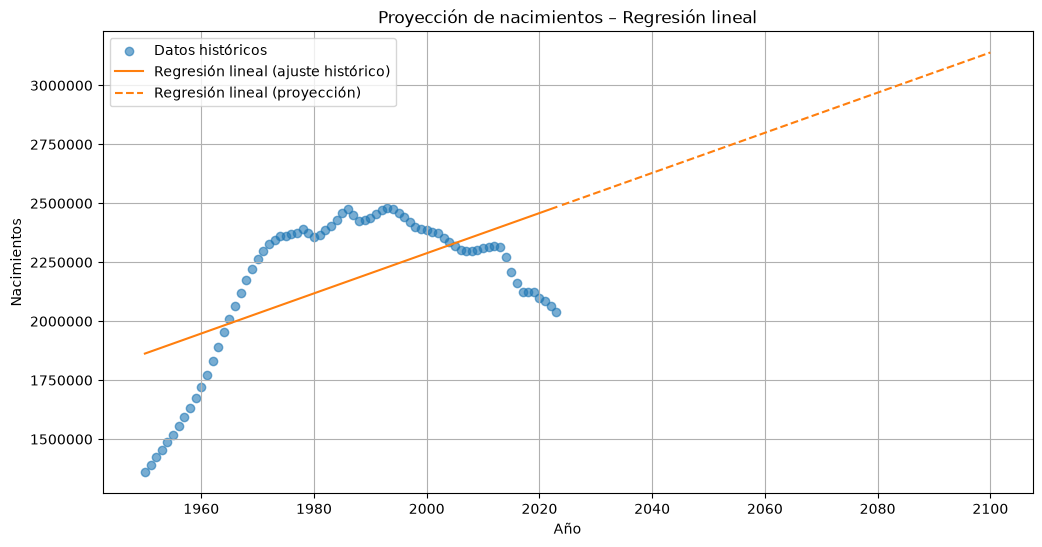

In [33]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df_historico["Year"],
    df_historico["births"],
    label="Datos históricos",
    alpha=0.6
)

# Ajuste del modelo sobre los años históricos
plt.plot(
    df_historico["Year"],
    predicciones_lineal,
    color="tab:orange",
    label="Regresión lineal (ajuste histórico)"
)

# Proyección hacia el futuro
plt.plot(
    anios_futuros.flatten(),
    predicciones_lineal_futuras,
    color="tab:orange",
    linestyle="--",
    label="Regresión lineal (proyección)"
)

plt.title("Proyección de nacimientos – Regresión lineal")
plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

### Observación

Analiza cómo continúa la tendencia histórica cuando utilizamos una **función lineal**. ¿Qué pasa con los valores hacia el año 2100?

*Respuesta:* La recta aprendida tiene pendiente positiva (aproximadamente +8,511 nacimientos por año), así que el modelo proyecta un **crecimiento constante**: cerca de 2.54 millones en 2030 y 3.14 millones en 2100. Esto contradice lo que se ve en los datos, donde los nacimientos vienen cayendo desde 1993. Lo que pasa es que la recta promedia toda la serie: el fuerte crecimiento de 1950-1993 pesa más que la caída reciente, y como una línea recta no puede cambiar de dirección, extiende hacia el futuro una tendencia que en realidad ya se revirtió.


# PARTE 9. Modelo 2 – Regresión polinomial

## 18. Crear variables polinomiales

La regresión lineal solamente puede representar una relación **lineal** entre las variables. Ahora construiremos variables polinomiales para permitir **curvas**. Utilizaremos un polinomio de **grado 2**:

$$y = a \cdot x^2 + b \cdot x + c$$

In [34]:
poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

Transformamos `X`:

In [35]:
X_poly = poly.fit_transform(X)

X_poly[:5]

array([[1.950000e+03, 3.802500e+06],
       [1.951000e+03, 3.806401e+06],
       [1.952000e+03, 3.810304e+06],
       [1.953000e+03, 3.814209e+06],
       [1.954000e+03, 3.818116e+06]])

Observa que ahora cada año tiene **dos columnas**: el año (`x`) y el año al cuadrado (`x²`).

## 19. Crear y entrenar el modelo polinomial

Seguimos utilizando `LinearRegression`; lo único que cambió son las **variables de entrada**.

In [36]:
modelo_polinomial = LinearRegression()

modelo_polinomial.fit(
    X_poly,
    y_nacimientos
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[2419436.24, -606.83]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.409e+09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2,)","[730030.32, 0.88]"


## 20. Generar predicciones históricas

In [37]:
predicciones_polinomiales = modelo_polinomial.predict(
    X_poly
)

## 21. Generar proyecciones hasta 2100

Transformamos los años futuros utilizando **el mismo objeto `poly`** con el que transformamos los datos de entrenamiento.

In [38]:
anios_futuros_poly = poly.transform(
    X_futuro
)

predicciones_polinomiales_futuras = modelo_polinomial.predict(
    anios_futuros_poly
)

# PARTE 10. Visualizar la regresión polinomial

## 22. Graficar las predicciones

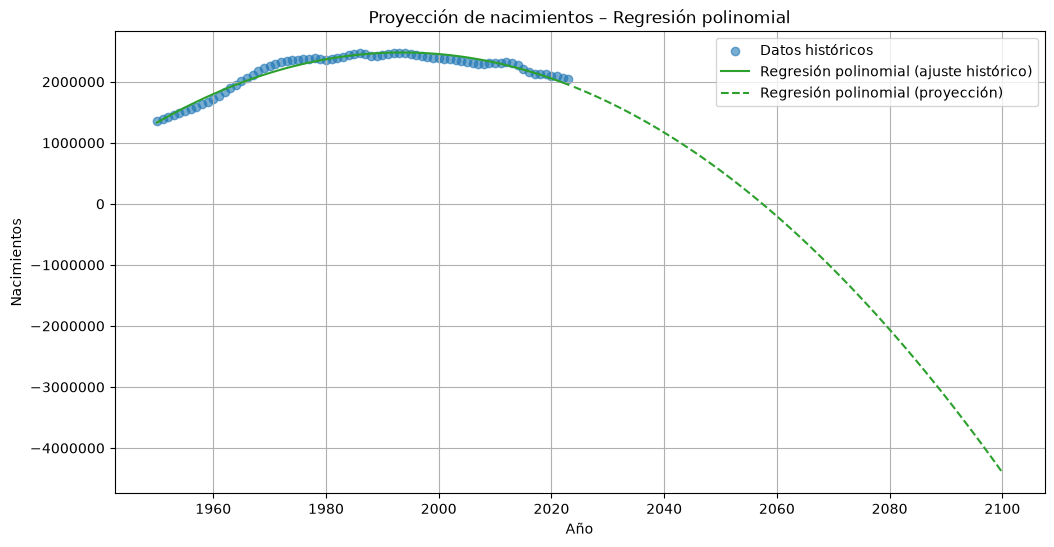

In [39]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df_historico["Year"],
    df_historico["births"],
    label="Datos históricos",
    alpha=0.6
)

plt.plot(
    df_historico["Year"],
    predicciones_polinomiales,
    color="tab:green",
    label="Regresión polinomial (ajuste histórico)"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_polinomiales_futuras,
    color="tab:green",
    linestyle="--",
    label="Regresión polinomial (proyección)"
)

plt.title("Proyección de nacimientos – Regresión polinomial")
plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

### Observación

Compara el comportamiento de esta gráfica con el modelo de regresión lineal. ¿Se ajusta mejor a los datos históricos? ¿Qué ocurre con la proyección hacia el año 2100? ¿Los valores que predice tienen sentido para un número de nacimientos?

*Respuesta:* Sí se ajusta bastante mejor al histórico, porque la parábola sí puede capturar la subida hasta los noventa y la bajada posterior. El problema aparece al extrapolar: el término cuadrático es negativo, así que la curva sigue cayendo cada vez más rápido. Predice alrededor de 1.67 millones en 2030 (razonable), pero solo 543 mil en 2050 y **valores negativos** a partir de aproximadamente 2060, llegando a -4.4 millones en 2100.

Esos valores **no tienen ningún sentido**: no existen nacimientos negativos. Un buen ajuste dentro del rango de entrenamiento no garantiza predicciones válidas fuera de él; el modelo no sabe que la variable tiene un límite físico en cero.


# PARTE 11. Modelo 3 – Random Forest

## 23. Crear el modelo

Un **Random Forest** está formado por muchos árboles de decisión. Utilizaremos `RandomForestRegressor`.

In [40]:
modelo_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

## 24. Entrenar el modelo

In [41]:
modelo_rf.fit(
    X,
    y_nacimientos
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

## 25. Generar predicciones históricas

In [42]:
predicciones_rf = modelo_rf.predict(X)

## 26. Generar proyecciones futuras

In [43]:
predicciones_rf_futuras = modelo_rf.predict(
    X_futuro
)

# PARTE 12. Visualizar Random Forest

## 27. Graficar las predicciones

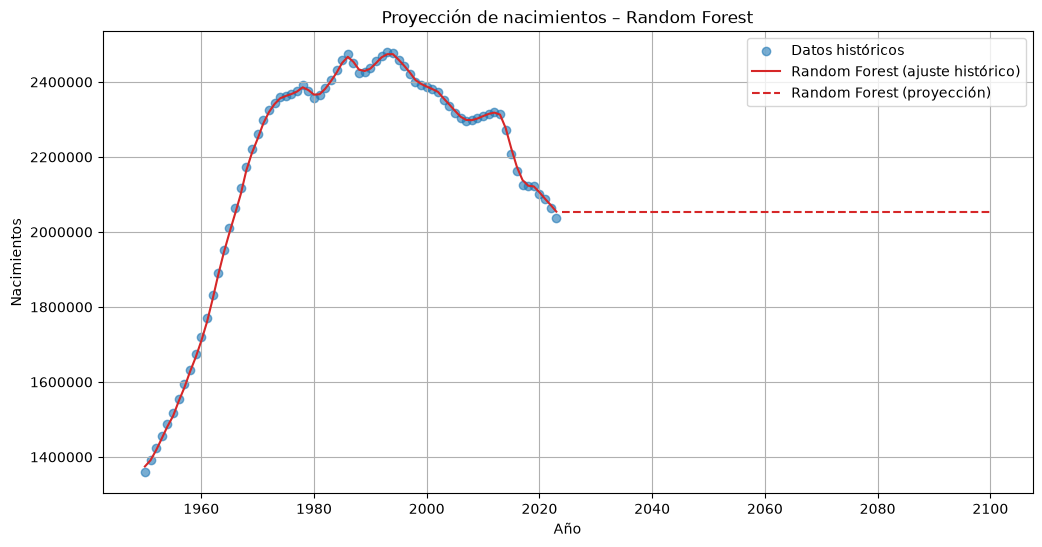

In [44]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df_historico["Year"],
    df_historico["births"],
    label="Datos históricos",
    alpha=0.6
)

plt.plot(
    df_historico["Year"],
    predicciones_rf,
    color="tab:red",
    label="Random Forest (ajuste histórico)"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_rf_futuras,
    color="tab:red",
    linestyle="--",
    label="Random Forest (proyección)"
)

plt.title("Proyección de nacimientos – Random Forest")
plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

### Observación

Fíjate en dos cosas: (1) qué tan bien sigue el modelo los datos históricos y (2) qué sucede con la línea después de 2023. ¿Continúa la tendencia? ¿Por qué crees que sucede esto? Investiga.

*Respuesta:*

1. **En el histórico es el que mejor se ajusta**, casi pasa por encima de cada punto. Tiene sentido: al entrenar y predecir sobre los mismos años, el bosque prácticamente memoriza los datos (sobreajuste).
2. **Después de 2023 la línea se vuelve completamente plana**, en aproximadamente 2,054,207 nacimientos, sin importar si el año es 2024 o 2100.

Esto ocurre porque un Random Forest es un conjunto de árboles de decisión, y un árbol solo aplica cortes del tipo "si Year > 2022, entonces...". Cada hoja guarda el **promedio de los valores de entrenamiento** que cayeron ahí. Cualquier año mayor al último visto (2023) cae siempre en la misma hoja terminal y devuelve siempre el mismo número. Por eso los modelos basados en árboles **no pueden extrapolar**: nunca predicen fuera del rango de valores con los que fueron entrenados. Los modelos lineales sí extrapolan (para bien o para mal), porque calculan la salida con una fórmula continua.


# PARTE 13. Comparar los tres modelos

## 28. Graficar los tres modelos

Construimos una gráfica que permita comparar directamente los resultados.

> Si la regresión polinomial genera valores muy extremos y no permite ver bien las demás curvas, puedes limitar el eje vertical agregando, por ejemplo, `plt.ylim(0, 3_500_000)` antes de `plt.show()`.

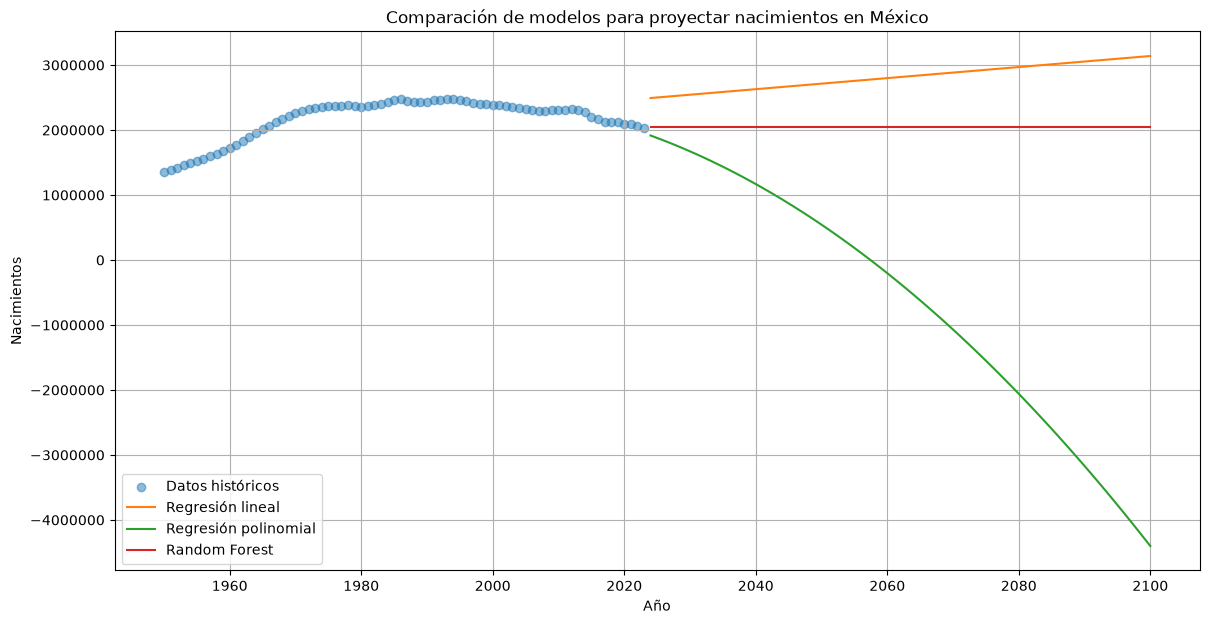

In [45]:
plt.figure(figsize=(14, 7))

plt.scatter(
    df_historico["Year"],
    df_historico["births"],
    label="Datos históricos",
    alpha=0.5
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_lineal_futuras,
    color="tab:orange",
    label="Regresión lineal"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_polinomiales_futuras,
    color="tab:green",
    label="Regresión polinomial"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_rf_futuras,
    color="tab:red",
    label="Random Forest"
)

plt.title(
    "Comparación de modelos para proyectar nacimientos en México"
)

plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

# PARTE 14. Repetir el proceso para defunciones

Hasta este momento construimos modelos para predecir **nacimientos**. Ahora repetiremos el mismo proceso para **defunciones**.

## 29. Preparar la variable objetivo

La variable predictora sigue siendo `X` (el año). Solo cambia la variable objetivo:

In [46]:
y_defunciones = df_historico["deaths"]

## 30. Regresión lineal para defunciones

In [47]:
modelo_lineal_deaths = LinearRegression()

modelo_lineal_deaths.fit(
    X,
    y_defunciones
)

predicciones_lineal_deaths = modelo_lineal_deaths.predict(
    X_futuro
)

## 31. Regresión polinomial para defunciones

Utilizamos nuevamente las variables construidas con `PolynomialFeatures` (`X_poly` y `anios_futuros_poly`).

In [48]:
modelo_polinomial_deaths = LinearRegression()

modelo_polinomial_deaths.fit(
    X_poly,
    y_defunciones
)

predicciones_polinomiales_deaths = modelo_polinomial_deaths.predict(
    anios_futuros_poly
)

## 32. Random Forest para defunciones

In [49]:
modelo_rf_deaths = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

modelo_rf_deaths.fit(
    X,
    y_defunciones
)

predicciones_rf_deaths = modelo_rf_deaths.predict(
    X_futuro
)

# PARTE 15. Comparar las predicciones de defunciones

## 33. Visualizar los tres modelos

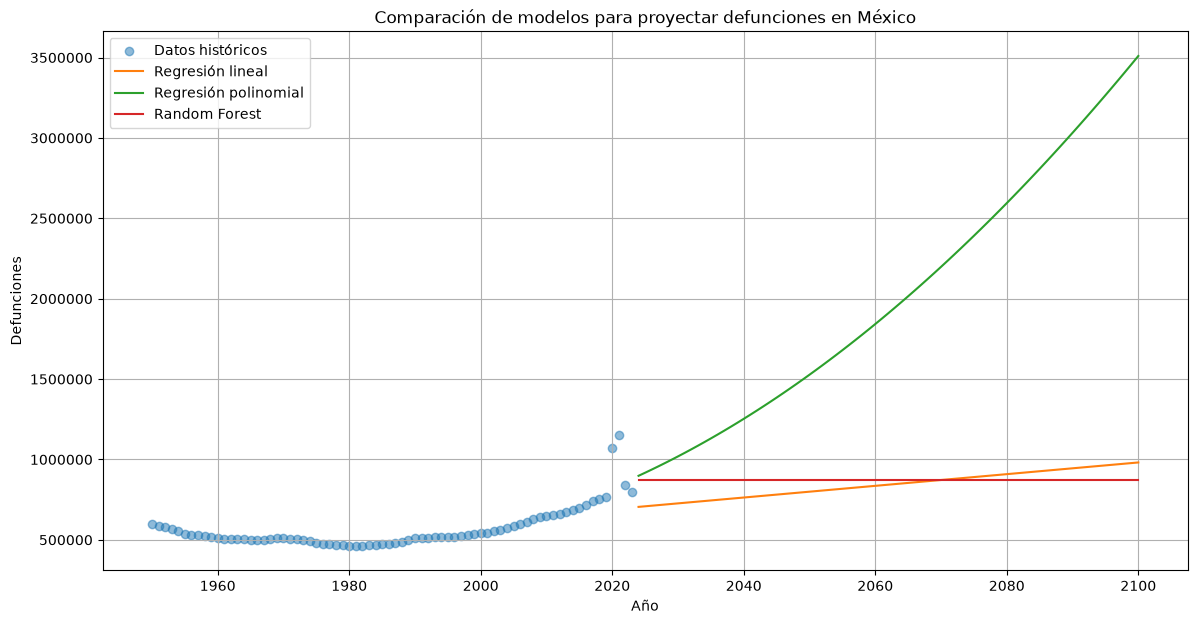

In [50]:
plt.figure(figsize=(14, 7))

plt.scatter(
    df_historico["Year"],
    df_historico["deaths"],
    label="Datos históricos",
    alpha=0.5
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_lineal_deaths,
    color="tab:orange",
    label="Regresión lineal"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_polinomiales_deaths,
    color="tab:green",
    label="Regresión polinomial"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_rf_deaths,
    color="tab:red",
    label="Random Forest"
)

plt.title(
    "Comparación de modelos para proyectar defunciones en México"
)

plt.xlabel("Año")
plt.ylabel("Defunciones")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

# PARTE 16. Comparar nuestros modelos con las proyecciones de OWID

Finalmente, agregamos a las gráficas las **proyecciones proporcionadas por OWID** (las de la ONU, escenario medio). Estas proyecciones no se obtienen ajustando una recta a la serie histórica: se construyen con modelos demográficos que consideran fecundidad, mortalidad y estructura por edad de la población.

## 34. Nacimientos: ML vs OWID

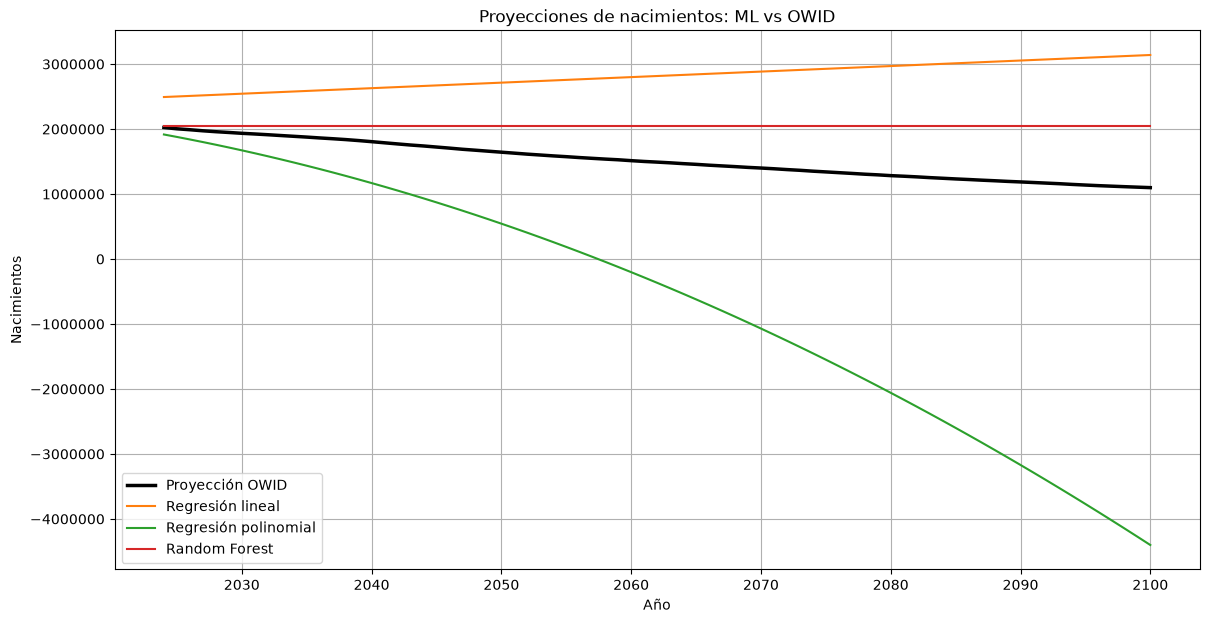

In [51]:
plt.figure(figsize=(14, 7))

plt.plot(
    df_proyectado["Year"],
    df_proyectado["births"],
    color="black",
    linewidth=2.5,
    label="Proyección OWID"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_lineal_futuras,
    color="tab:orange",
    label="Regresión lineal"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_polinomiales_futuras,
    color="tab:green",
    label="Regresión polinomial"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_rf_futuras,
    color="tab:red",
    label="Random Forest"
)

plt.title(
    "Proyecciones de nacimientos: ML vs OWID"
)

plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

## 35. Defunciones: ML vs OWID

Repetimos el ejercicio para defunciones.

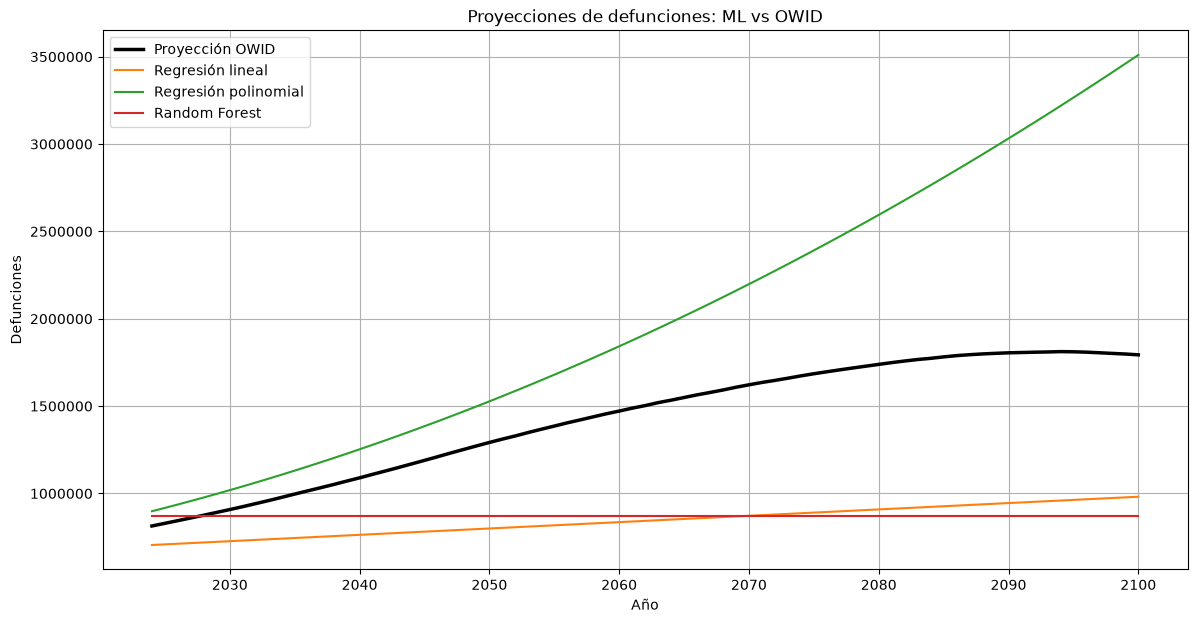

In [52]:
plt.figure(figsize=(14, 7))

plt.plot(
    df_proyectado["Year"],
    df_proyectado["deaths"],
    color="black",
    linewidth=2.5,
    label="Proyección OWID"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_lineal_deaths,
    color="tab:orange",
    label="Regresión lineal"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_polinomiales_deaths,
    color="tab:green",
    label="Regresión polinomial"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_rf_deaths,
    color="tab:red",
    label="Random Forest"
)

plt.title(
    "Proyecciones de defunciones: ML vs OWID"
)

plt.xlabel("Año")
plt.ylabel("Defunciones")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

## 36. Resumen numérico (opcional)

A veces es útil ver los números y no solo la gráfica. Esta tabla muestra lo que predice cada modelo para algunos años seleccionados:

In [53]:
anios_tabla = [2030, 2050, 2075, 2100]
indice = anios_futuros.flatten()


def construir_tabla(owid, lineal, polinomial, rf):
    tabla = pd.DataFrame(
        {
            "OWID": owid.set_index("Year").reindex(indice).to_numpy().ravel(),
            "Regresión lineal": lineal,
            "Regresión polinomial": polinomial,
            "Random Forest": rf,
        },
        index=indice
    )
    tabla.index.name = "Año"
    return tabla.loc[anios_tabla]


print("NACIMIENTOS")
display(
    construir_tabla(
        df_proyectado[["Year", "births"]],
        predicciones_lineal_futuras,
        predicciones_polinomiales_futuras,
        predicciones_rf_futuras
    ).style.format("{:,.0f}")
)

print("DEFUNCIONES")
display(
    construir_tabla(
        df_proyectado[["Year", "deaths"]],
        predicciones_lineal_deaths,
        predicciones_polinomiales_deaths,
        predicciones_rf_deaths
    ).style.format("{:,.0f}")
)

NACIMIENTOS


,OWID,Regresión lineal,Regresión polinomial,Random Forest
Año,,,,
2030,"1,934,285","2,543,559","1,672,155","2,054,207"
2050,"1,643,767","2,713,775","543,760","2,054,207"
2075,"1,340,246","2,926,545","-1,549,414","2,054,207"
2100,"1,098,210","3,139,315","-4,401,123","2,054,207"


DEFUNCIONES


,OWID,Regresión lineal,Regresión polinomial,Random Forest
Año,,,,
2030,"907,843","726,810","1,019,007","869,570"
2050,"1,291,889","799,521","1,527,163","869,570"
2075,"1,685,181","890,408","2,391,272","869,570"
2100,"1,793,462","981,296","3,509,731","869,570"


# PARTE 17. Reflexión

Responde las siguientes preguntas en esta misma celda (haz doble clic para editarla).

### 1.
¿Qué diferencia observaste entre la regresión lineal, la regresión polinomial y Random Forest?

*Respuesta:* La **lineal** traza una sola recta: no se ajusta bien al histórico (ignora el quiebre de 1993) pero al menos genera proyecciones estables. La **polinomial** de grado 2 sí sigue la forma de la curva histórica, aunque al extrapolar se dispara y termina en valores absurdos. El **Random Forest** es el que mejor reproduce el histórico, casi punto por punto, pero a partir de 2024 devuelve siempre el mismo valor constante. En resumen: cada uno falla de una manera distinta según qué tan flexible es y cómo se comporta fuera del rango de entrenamiento.

### 2.
¿Por qué los tres modelos generan predicciones diferentes si utilizaron los mismos datos históricos?

*Respuesta:* Porque cada algoritmo parte de una **suposición distinta sobre la forma de la relación** entre el año y los nacimientos. La regresión lineal asume que la relación es una recta, la polinomial asume una parábola, y el Random Forest no asume ninguna función: parte el rango de años en intervalos y promedia. Los datos son los mismos, pero cada modelo los interpreta con una familia de funciones diferente, así que aprende algo diferente. Esa elección de modelo es una decisión del analista, y pesa tanto como los propios datos.

### 3.
¿Qué modelo produjo una tendencia más cercana visualmente a las proyecciones de OWID?

*Respuesta:* Depende de la variable, y ninguno se acerca realmente:

- En **nacimientos**, OWID baja de manera gradual (1.93 millones en 2030 a 1.10 millones en 2100). Ningún modelo reproduce eso: la lineal sube, la polinomial se va a negativos y el RF se queda plano. En el corto plazo (2030) la polinomial es la más cercana; en el largo plazo el Random Forest es el menos disparatado, aunque solo porque quedarse quieto es mejor que equivocarse en la dirección.
- En **defunciones**, OWID crece fuerte (de 908 mil en 2030 a 1.79 millones en 2100), y ahí la **polinomial** es la que acompaña mejor la dirección, aunque se pasa de largo (3.5 millones en 2100).

### 4.
¿El modelo que visualmente parece acercarse más a las proyecciones de OWID necesariamente es el mejor modelo? Explica.

*Respuesta:* No. Parecerse a OWID en una gráfica no es evidencia de que el modelo sea bueno, por varias razones. Primero, OWID no es la verdad: también es una proyección, construida con modelos demográficos que consideran fecundidad, mortalidad y estructura por edad, es decir, información que nuestros modelos ni siquiera tienen. Segundo, un parecido puede ser pura coincidencia; la polinomial acierta la dirección de las defunciones por la forma de la parábola, no porque entienda de demografía. Y tercero, "verse bien" no es una métrica: para comparar modelos en serio hay que evaluar con datos que el modelo no vio durante el entrenamiento y usar medidas como MAE o RMSE.

### 5.
¿Qué comportamiento observaste en las predicciones de Random Forest para los años posteriores a 2023?

*Respuesta:* Una **línea perfectamente horizontal**. Predice aproximadamente 2,054,207 nacimientos y 869,570 defunciones para absolutamente todos los años de 2024 a 2100. Como se explicó arriba, los árboles solo dividen el espacio con umbrales y devuelven el promedio de la hoja: todos los años posteriores a 2023 caen en la misma hoja final y reciben el mismo valor. Un modelo basado en árboles no puede extrapolar fuera del rango de entrenamiento.

### 6.
¿Por qué debemos tener cuidado al utilizar un modelo entrenado con datos históricos para realizar predicciones hasta el año 2100?

*Respuesta:* Porque estaríamos **extrapolando muy lejos**: entrenamos con 74 años de datos y pedimos 77 años hacia adelante, un horizonte más largo que la propia historia observada. Ahí ya no hay nada que valide al modelo. Además:

- El modelo solo vio la relación año-nacimientos, no las causas reales (fecundidad, migración, esperanza de vida, políticas públicas), y esas causas pueden cambiar.
- Nada garantiza que las tendencias pasadas continúen; los propios datos muestran quiebres (1993 en nacimientos, la pandemia en defunciones) que ningún modelo habría anticipado.
- Los modelos no conocen los límites físicos de la variable, por eso la polinomial llega a predecir nacimientos negativos.
- Los errores se acumulan: mientras más lejos proyectamos, más se amplifica cualquier desviación pequeña del ajuste.

Como regla práctica, estos modelos son razonables para horizontes cortos y cercanos al rango de entrenamiento. Para proyecciones a 2100 se requieren modelos demográficos que representen explícitamente el mecanismo de la población, como los que usa la ONU.


# PARTE 18. Conceptos clave

Al finalizar la práctica, debes poder identificar:

| Concepto | Significado |
|---|---|
| **Variable predictora** | Variable utilizada por el modelo para generar una predicción |
| **Variable objetivo** | Variable que queremos predecir |
| **Entrenamiento** | Proceso mediante el cual el modelo aprende a partir de los datos |
| **Predicción** | Resultado generado por el modelo |
| **Regresión lineal** | Modelo que representa una relación lineal |
| **Regresión polinomial** | Extensión que permite representar relaciones curvas |
| **Random Forest** | Modelo basado en múltiples árboles de decisión |
| **Extrapolación** | Generación de predicciones fuera del rango de datos utilizados para entrenar el modelo |

> **Importante:** En esta práctica solamente hemos **construido y utilizado** los modelos. En la siguiente práctica aprenderemos a **evaluar su desempeño mediante métricas**, para determinar qué tan bien están realizando sus predicciones.

---

# EJERCICIOS ADICIONALES

---

# Ejercicio 1 — Extraer el país de China

Se repite el mismo flujo de trabajo que se utilizó con México:
1. Filtrar los datos de China.
2. Separar histórico (≤ 2023) y proyectado (> 2023).
3. Entrenar los tres modelos (Regresión Lineal, Regresión Polinomial, Random Forest) sobre **nacimientos** y **defunciones**.
4. Graficar las predicciones de cada modelo junto con los datos históricos y las proyecciones de OWID.

## Filtrar los datos de China

In [54]:
pais_china = "China"

df_china = df[df["Entity"] == pais_china]

print("Rango de años:", df_china["Year"].min(), "-", df_china["Year"].max())
print("Número de filas:", df_china.shape[0])
df_china.head()

Rango de años: 1950 - 2100
Número de filas: 151


,Entity,Code,Year,deaths_estimates,deaths_projected,births_estimates,births_projected,births,deaths
7097,China,CHN,1950,12564023.0,NaN,22293376.0,NaN,22293376.0,12564023.0
7098,China,CHN,1951,12411701.0,NaN,22144814.0,NaN,22144814.0,12411701.0
7099,China,CHN,1952,12459848.0,NaN,25496318.0,NaN,25496318.0,12459848.0
7100,China,CHN,1953,12309525.0,NaN,24139416.0,NaN,24139416.0,12309525.0
7101,China,CHN,1954,12145578.0,NaN,25438544.0,NaN,25438544.0,12145578.0


## Separar datos históricos y proyectados

In [55]:
df_hist_china = df_china[df_china["Year"] <= 2023]
df_proy_china = df_china[df_china["Year"] > 2023]

print("Histórico  ->", df_hist_china.shape, "| años:", df_hist_china["Year"].min(), "a", df_hist_china["Year"].max())
print("Proyectado ->", df_proy_china.shape, "| años:", df_proy_china["Year"].min(), "a", df_proy_china["Year"].max())

Histórico  -> (74, 9) | años: 1950 a 2023
Proyectado -> (77, 9) | años: 2024 a 2100


## Gráficas exploratorias de nacimientos y defunciones en China

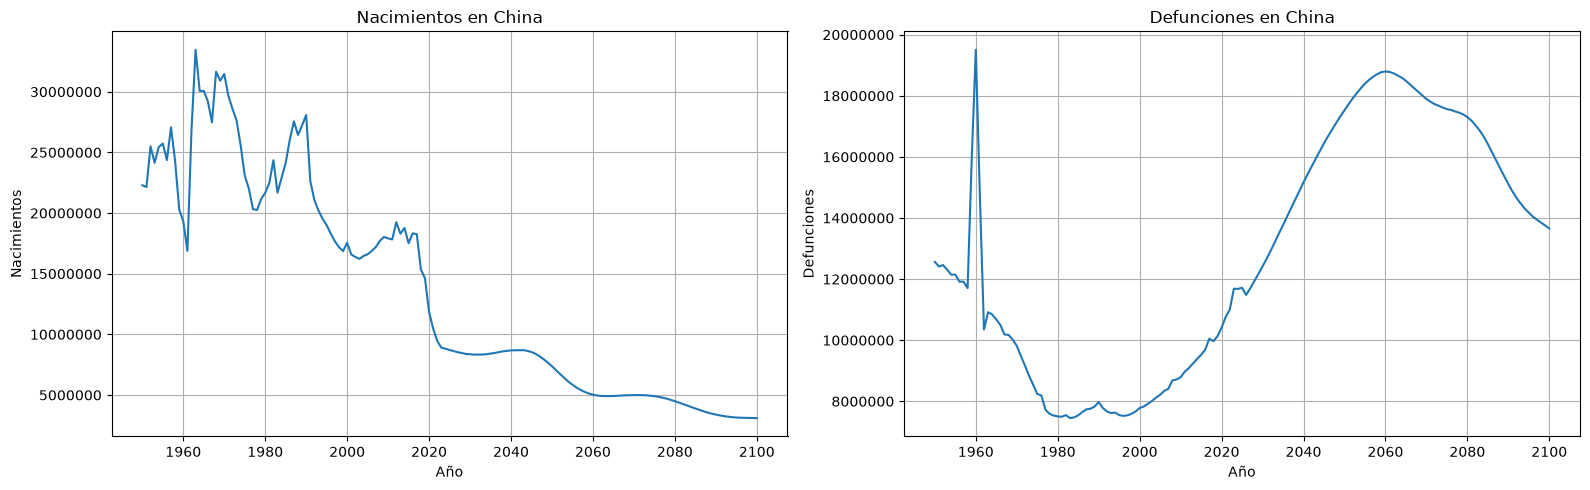

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(df_china["Year"], df_china["births"])
axes[0].set_title("Nacimientos en China")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Nacimientos")
axes[0].ticklabel_format(style="plain", axis="y", useOffset=False)
axes[0].grid()

axes[1].plot(df_china["Year"], df_china["deaths"])
axes[1].set_title("Defunciones en China")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Defunciones")
axes[1].ticklabel_format(style="plain", axis="y", useOffset=False)
axes[1].grid()

plt.tight_layout()
plt.show()

## Preparar datos para los modelos

In [57]:
X_china = df_hist_china[["Year"]]
y_nac_china = df_hist_china["births"]
y_def_china = df_hist_china["deaths"]

anios_futuros_china = np.arange(2024, 2101).reshape(-1, 1)
X_futuro_china = pd.DataFrame(anios_futuros_china, columns=["Year"])

print("X_china:", X_china.shape)
print("y_nac_china:", y_nac_china.shape)
print("y_def_china:", y_def_china.shape)

X_china: (74, 1)
y_nac_china: (74,)
y_def_china: (74,)


## Entrenar los 3 modelos — Nacimientos en China

In [58]:
# --- Regresión Lineal ---
rl_china_nac = LinearRegression()
rl_china_nac.fit(X_china, y_nac_china)
pred_rl_china_nac = rl_china_nac.predict(X_futuro_china)

# --- Regresión Polinomial (grado 2) ---
poly_china = PolynomialFeatures(degree=2, include_bias=False)
X_poly_china = poly_china.fit_transform(X_china)
X_futuro_poly_china = poly_china.transform(X_futuro_china)

rp_china_nac = LinearRegression()
rp_china_nac.fit(X_poly_china, y_nac_china)
pred_rp_china_nac = rp_china_nac.predict(X_futuro_poly_china)

# --- Random Forest ---
rf_china_nac = RandomForestRegressor(n_estimators=100, random_state=42)
rf_china_nac.fit(X_china, y_nac_china)
pred_rf_china_nac = rf_china_nac.predict(X_futuro_china)

print("Modelos de nacimientos para China entrenados correctamente.")

Modelos de nacimientos para China entrenados correctamente.


## Entrenar los 3 modelos — Defunciones en China

In [59]:
# --- Regresión Lineal ---
rl_china_def = LinearRegression()
rl_china_def.fit(X_china, y_def_china)
pred_rl_china_def = rl_china_def.predict(X_futuro_china)

# --- Regresión Polinomial (grado 2) ---
rp_china_def = LinearRegression()
rp_china_def.fit(X_poly_china, y_def_china)
pred_rp_china_def = rp_china_def.predict(X_futuro_poly_china)

# --- Random Forest ---
rf_china_def = RandomForestRegressor(n_estimators=100, random_state=42)
rf_china_def.fit(X_china, y_def_china)
pred_rf_china_def = rf_china_def.predict(X_futuro_china)

print("Modelos de defunciones para China entrenados correctamente.")

Modelos de defunciones para China entrenados correctamente.


## Gráfica comparativa — Nacimientos en China (3 modelos + OWID)

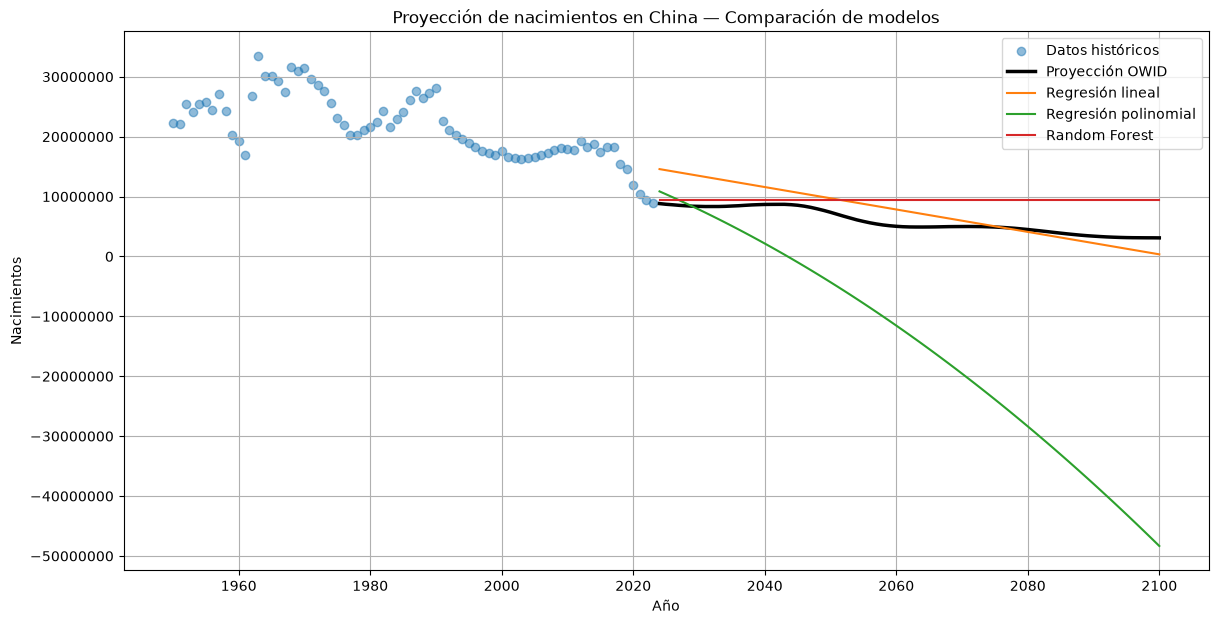

In [60]:
plt.figure(figsize=(14, 7))

plt.scatter(
    df_hist_china["Year"],
    df_hist_china["births"],
    label="Datos históricos",
    alpha=0.5
)

plt.plot(
    df_proy_china["Year"],
    df_proy_china["births"],
    color="black",
    linewidth=2.5,
    label="Proyección OWID"
)

plt.plot(
    anios_futuros_china.flatten(),
    pred_rl_china_nac,
    color="tab:orange",
    label="Regresión lineal"
)

plt.plot(
    anios_futuros_china.flatten(),
    pred_rp_china_nac,
    color="tab:green",
    label="Regresión polinomial"
)

plt.plot(
    anios_futuros_china.flatten(),
    pred_rf_china_nac,
    color="tab:red",
    label="Random Forest"
)

plt.title("Proyección de nacimientos en China — Comparación de modelos")
plt.xlabel("Año")
plt.ylabel("Nacimientos")
plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

## Gráfica comparativa — Defunciones en China (3 modelos + OWID)

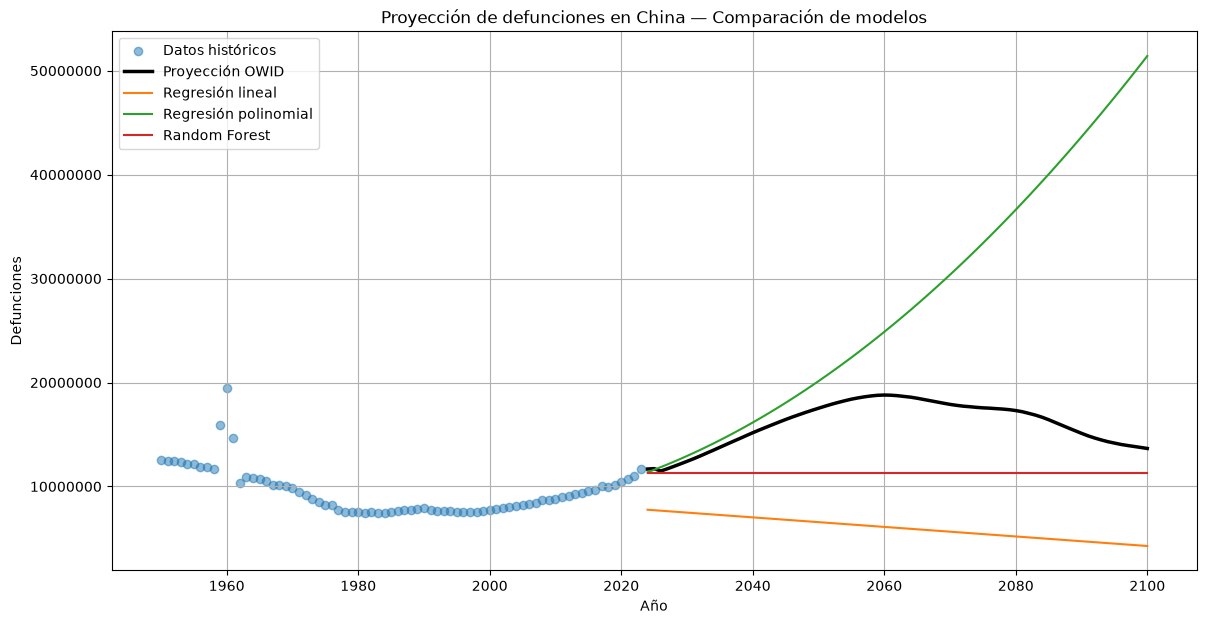

In [61]:
plt.figure(figsize=(14, 7))

plt.scatter(
    df_hist_china["Year"],
    df_hist_china["deaths"],
    label="Datos históricos",
    alpha=0.5
)

plt.plot(
    df_proy_china["Year"],
    df_proy_china["deaths"],
    color="black",
    linewidth=2.5,
    label="Proyección OWID"
)

plt.plot(
    anios_futuros_china.flatten(),
    pred_rl_china_def,
    color="tab:orange",
    label="Regresión lineal"
)

plt.plot(
    anios_futuros_china.flatten(),
    pred_rp_china_def,
    color="tab:green",
    label="Regresión polinomial"
)

plt.plot(
    anios_futuros_china.flatten(),
    pred_rf_china_def,
    color="tab:red",
    label="Random Forest"
)

plt.title("Proyección de defunciones en China — Comparación de modelos")
plt.xlabel("Año")
plt.ylabel("Defunciones")
plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

## Tabla resumen — China

In [62]:
anios_tabla_china = [2030, 2050, 2075, 2100]
indice_china = anios_futuros_china.flatten()


def construir_tabla_china(owid, lineal, polinomial, rf):
    tabla = pd.DataFrame(
        {
            "OWID": owid.set_index("Year").reindex(indice_china).to_numpy().ravel(),
            "Regresión lineal": lineal,
            "Regresión polinomial": polinomial,
            "Random Forest": rf,
        },
        index=indice_china
    )
    tabla.index.name = "Año"
    return tabla.loc[anios_tabla_china]


print("NACIMIENTOS — CHINA")
display(
    construir_tabla_china(
        df_proy_china[["Year", "births"]],
        pred_rl_china_nac,
        pred_rp_china_nac,
        pred_rf_china_nac
    ).style.format("{:,.0f}")
)

print("\nDEFUNCIONES — CHINA")
display(
    construir_tabla_china(
        df_proy_china[["Year", "deaths"]],
        pred_rl_china_def,
        pred_rp_china_def,
        pred_rf_china_def
    ).style.format("{:,.0f}")
)

NACIMIENTOS — CHINA


,OWID,Regresión lineal,Regresión polinomial,Random Forest
Año,,,,
2030,"8,359,513","13,456,651","7,830,199","9,489,420"
2050,"7,371,348","9,712,484","-4,298,790","9,489,420"
2075,"4,909,046","5,032,277","-23,867,936","9,489,420"
2100,"3,099,844","352,069","-48,334,758","9,489,420"



DEFUNCIONES — CHINA


,OWID,Regresión lineal,Regresión polinomial,Random Forest
Año,,,,
2030,"12,415,078","7,485,699","12,933,834","11,339,159"
2050,"17,526,300","6,567,577","20,134,799","11,339,159"
2075,"17,564,112","5,419,925","33,404,217","11,339,159"
2100,"13,655,445","4,272,272","51,416,093","11,339,159"


---

# Ejercicio 2 — Nacimientos / Defunciones a partir de 2000 en México

Se repite el análisis pero usando **únicamente datos históricos desde el año 2000** en México.
Esto permite observar cómo cambian las predicciones de los modelos al entrenarlos con un rango más reciente de datos.

## Filtrar datos históricos de México a partir del año 2000

In [63]:
df_mexico_2000 = df_mexico[
    (df_mexico["Year"] >= 2000) & (df_mexico["Year"] <= 2023)
]

print("Rango de años:", df_mexico_2000["Year"].min(), "-", df_mexico_2000["Year"].max())
print("Número de filas:", df_mexico_2000.shape[0])
df_mexico_2000.head()

Rango de años: 2000 - 2023
Número de filas: 24


,Entity,Code,Year,deaths_estimates,deaths_projected,births_estimates,births_projected,births,deaths
22851,Mexico,MEX,2000,540567.0,NaN,2385977.0,NaN,2385977.0,540567.0
22852,Mexico,MEX,2001,543803.0,NaN,2380261.0,NaN,2380261.0,543803.0
22853,Mexico,MEX,2002,553391.0,NaN,2374140.0,NaN,2374140.0,553391.0
22854,Mexico,MEX,2003,563140.0,NaN,2351177.0,NaN,2351177.0,563140.0
22855,Mexico,MEX,2004,575925.0,NaN,2335226.0,NaN,2335226.0,575925.0


## Gráficas exploratorias — México desde 2000

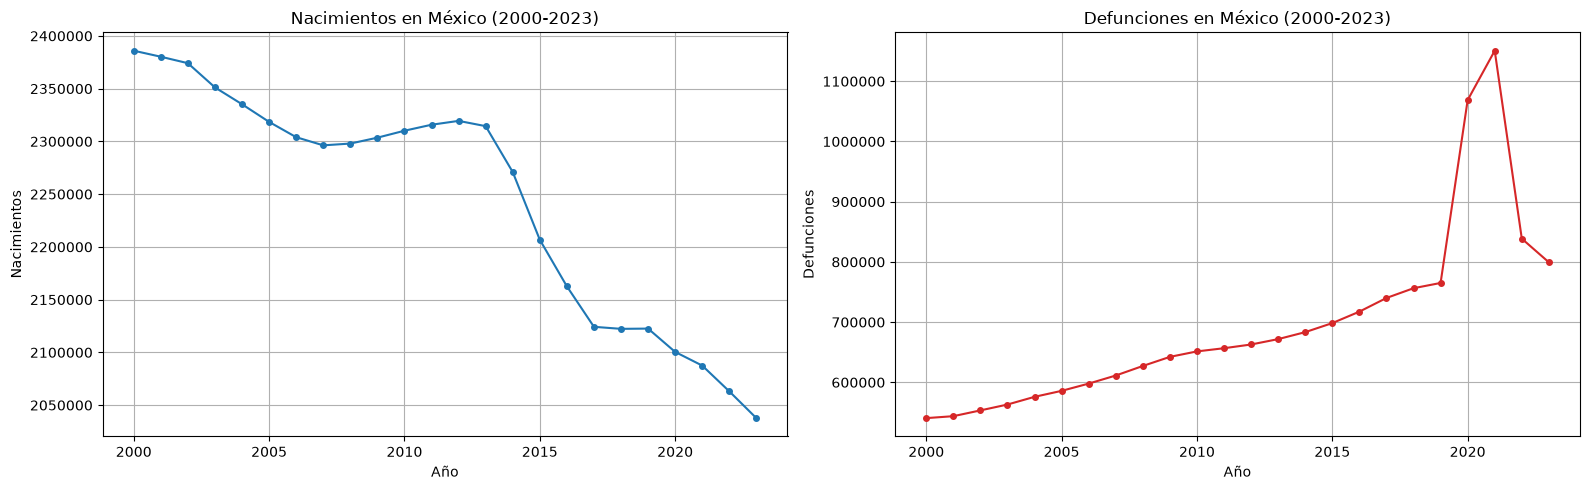

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(df_mexico_2000["Year"], df_mexico_2000["births"], marker="o", markersize=4)
axes[0].set_title("Nacimientos en México (2000-2023)")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Nacimientos")
axes[0].ticklabel_format(style="plain", axis="y", useOffset=False)
axes[0].grid()

axes[1].plot(df_mexico_2000["Year"], df_mexico_2000["deaths"], marker="o", markersize=4, color="tab:red")
axes[1].set_title("Defunciones en México (2000-2023)")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Defunciones")
axes[1].ticklabel_format(style="plain", axis="y", useOffset=False)
axes[1].grid()

plt.tight_layout()
plt.show()

## Preparar datos para los modelos

In [65]:
X_mex2000 = df_mexico_2000[["Year"]]
y_nac_mex2000 = df_mexico_2000["births"]
y_def_mex2000 = df_mexico_2000["deaths"]

# Reutilizamos los mismos años futuros (2024-2100)
anios_futuros_mex = np.arange(2024, 2101).reshape(-1, 1)
X_futuro_mex = pd.DataFrame(anios_futuros_mex, columns=["Year"])

print("X_mex2000:", X_mex2000.shape)
print("y_nac_mex2000:", y_nac_mex2000.shape)
print("y_def_mex2000:", y_def_mex2000.shape)

X_mex2000: (24, 1)
y_nac_mex2000: (24,)
y_def_mex2000: (24,)


## Entrenar los 3 modelos — Nacimientos en México (desde 2000)

In [66]:
# --- Regresión Lineal ---
rl_mex2000_nac = LinearRegression()
rl_mex2000_nac.fit(X_mex2000, y_nac_mex2000)
pred_rl_mex2000_nac = rl_mex2000_nac.predict(X_futuro_mex)

# --- Regresión Polinomial (grado 2) ---
poly_mex2000 = PolynomialFeatures(degree=2, include_bias=False)
X_poly_mex2000 = poly_mex2000.fit_transform(X_mex2000)
X_futuro_poly_mex2000 = poly_mex2000.transform(X_futuro_mex)

rp_mex2000_nac = LinearRegression()
rp_mex2000_nac.fit(X_poly_mex2000, y_nac_mex2000)
pred_rp_mex2000_nac = rp_mex2000_nac.predict(X_futuro_poly_mex2000)

# --- Random Forest ---
rf_mex2000_nac = RandomForestRegressor(n_estimators=100, random_state=42)
rf_mex2000_nac.fit(X_mex2000, y_nac_mex2000)
pred_rf_mex2000_nac = rf_mex2000_nac.predict(X_futuro_mex)

print("Modelos de nacimientos (México desde 2000) entrenados correctamente.")

Modelos de nacimientos (México desde 2000) entrenados correctamente.


## Entrenar los 3 modelos — Defunciones en México (desde 2000)

In [67]:
# --- Regresión Lineal ---
rl_mex2000_def = LinearRegression()
rl_mex2000_def.fit(X_mex2000, y_def_mex2000)
pred_rl_mex2000_def = rl_mex2000_def.predict(X_futuro_mex)

# --- Regresión Polinomial (grado 2) ---
rp_mex2000_def = LinearRegression()
rp_mex2000_def.fit(X_poly_mex2000, y_def_mex2000)
pred_rp_mex2000_def = rp_mex2000_def.predict(X_futuro_poly_mex2000)

# --- Random Forest ---
rf_mex2000_def = RandomForestRegressor(n_estimators=100, random_state=42)
rf_mex2000_def.fit(X_mex2000, y_def_mex2000)
pred_rf_mex2000_def = rf_mex2000_def.predict(X_futuro_mex)

print("Modelos de defunciones (México desde 2000) entrenados correctamente.")

Modelos de defunciones (México desde 2000) entrenados correctamente.


## Gráfica comparativa — Nacimientos en México (entrenado desde 2000 + OWID)

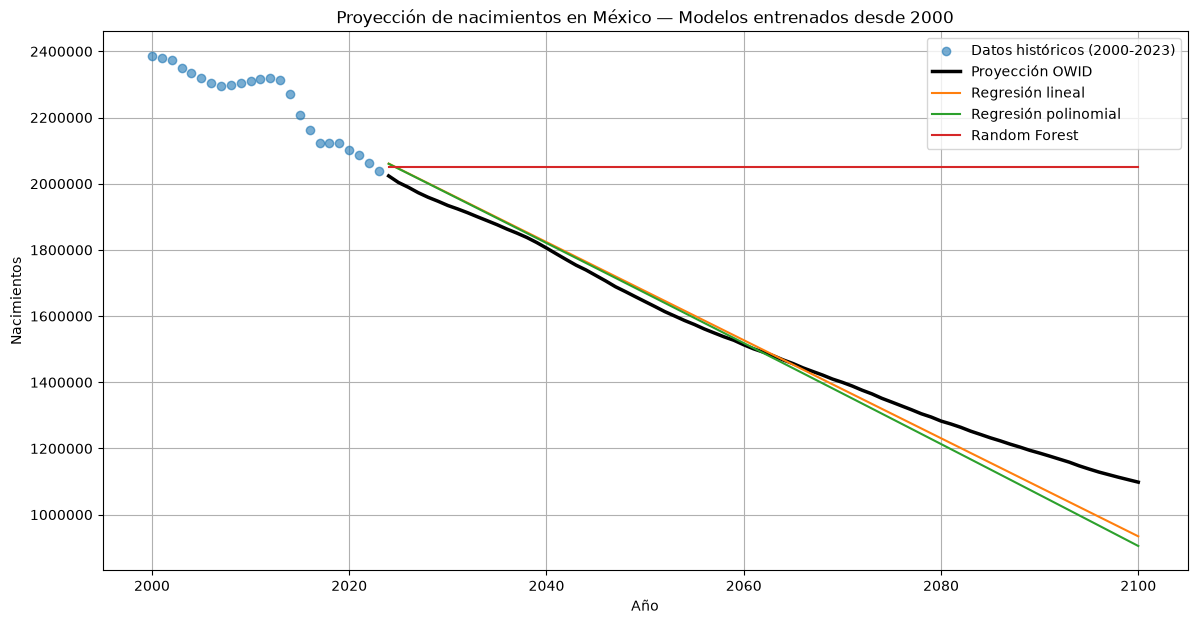

In [68]:
plt.figure(figsize=(14, 7))

plt.scatter(
    df_mexico_2000["Year"],
    df_mexico_2000["births"],
    label="Datos históricos (2000-2023)",
    alpha=0.6,
    zorder=5
)

plt.plot(
    df_proyectado["Year"],
    df_proyectado["births"],
    color="black",
    linewidth=2.5,
    label="Proyección OWID"
)

plt.plot(
    anios_futuros_mex.flatten(),
    pred_rl_mex2000_nac,
    color="tab:orange",
    label="Regresión lineal"
)

plt.plot(
    anios_futuros_mex.flatten(),
    pred_rp_mex2000_nac,
    color="tab:green",
    label="Regresión polinomial"
)

plt.plot(
    anios_futuros_mex.flatten(),
    pred_rf_mex2000_nac,
    color="tab:red",
    label="Random Forest"
)

plt.title("Proyección de nacimientos en México — Modelos entrenados desde 2000")
plt.xlabel("Año")
plt.ylabel("Nacimientos")
plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

## Gráfica comparativa — Defunciones en México (entrenado desde 2000 + OWID)

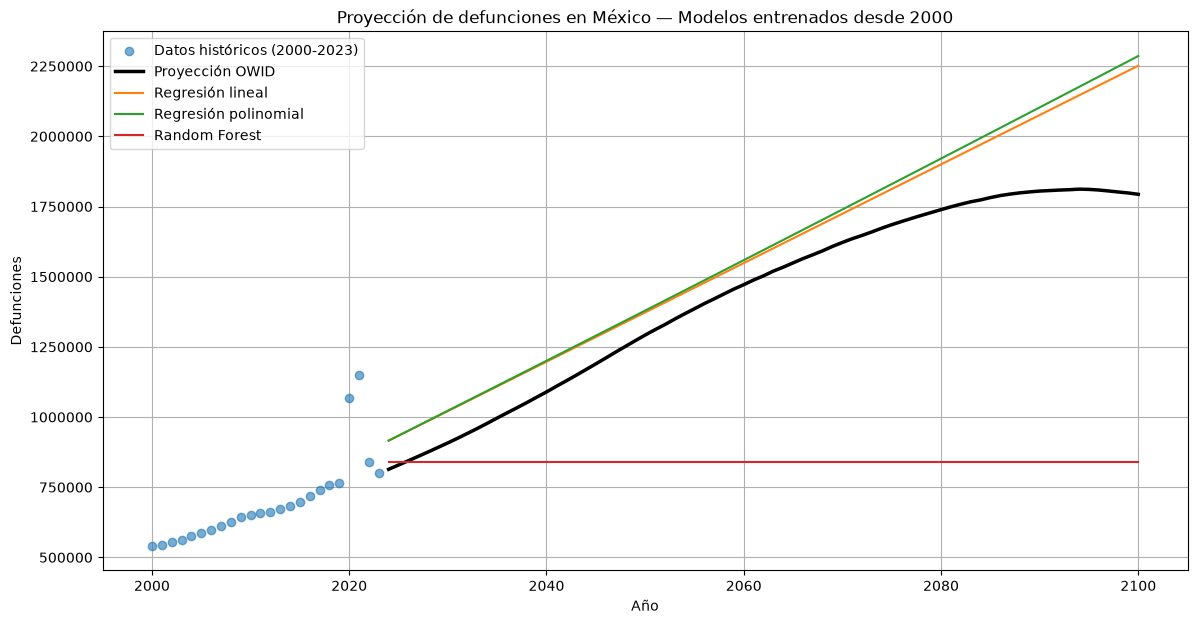

In [69]:
plt.figure(figsize=(14, 7))

plt.scatter(
    df_mexico_2000["Year"],
    df_mexico_2000["deaths"],
    label="Datos históricos (2000-2023)",
    alpha=0.6,
    zorder=5
)

plt.plot(
    df_proyectado["Year"],
    df_proyectado["deaths"],
    color="black",
    linewidth=2.5,
    label="Proyección OWID"
)

plt.plot(
    anios_futuros_mex.flatten(),
    pred_rl_mex2000_def,
    color="tab:orange",
    label="Regresión lineal"
)

plt.plot(
    anios_futuros_mex.flatten(),
    pred_rp_mex2000_def,
    color="tab:green",
    label="Regresión polinomial"
)

plt.plot(
    anios_futuros_mex.flatten(),
    pred_rf_mex2000_def,
    color="tab:red",
    label="Random Forest"
)

plt.title("Proyección de defunciones en México — Modelos entrenados desde 2000")
plt.xlabel("Año")
plt.ylabel("Defunciones")
plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

## Tabla resumen — México (entrenado desde 2000)

In [70]:
anios_tabla_mex = [2030, 2050, 2075, 2100]
indice_mex = anios_futuros_mex.flatten()


def construir_tabla_mex2000(owid, lineal, polinomial, rf):
    tabla = pd.DataFrame(
        {
            "OWID": owid.set_index("Year").reindex(indice_mex).to_numpy().ravel(),
            "Regresión lineal": lineal,
            "Regresión polinomial": polinomial,
            "Random Forest": rf,
        },
        index=indice_mex
    )
    tabla.index.name = "Año"
    return tabla.loc[anios_tabla_mex]


print("NACIMIENTOS — MÉXICO (desde 2000)")
display(
    construir_tabla_mex2000(
        df_proyectado[["Year", "births"]],
        pred_rl_mex2000_nac,
        pred_rp_mex2000_nac,
        pred_rf_mex2000_nac
    ).style.format("{:,.0f}")
)

print("\nDEFUNCIONES — MÉXICO (desde 2000)")
display(
    construir_tabla_mex2000(
        df_proyectado[["Year", "deaths"]],
        pred_rl_mex2000_def,
        pred_rp_mex2000_def,
        pred_rf_mex2000_def
    ).style.format("{:,.0f}")
)

NACIMIENTOS — MÉXICO (desde 2000)


,OWID,Regresión lineal,Regresión polinomial,Random Forest
Año,,,,
2030,"1,934,285","1,971,876","1,970,689","2,051,955"
2050,"1,643,767","1,675,481","1,669,982","2,051,955"
2075,"1,340,246","1,304,988","1,289,953","2,051,955"
2100,"1,098,210","934,494","905,317","2,051,955"



DEFUNCIONES — MÉXICO (desde 2000)


,OWID,Regresión lineal,Regresión polinomial,Random Forest
Año,,,,
2030,"907,843","1,021,129","1,022,528","838,793"
2050,"1,291,889","1,372,705","1,379,209","838,793"
2075,"1,685,181","1,812,175","1,829,978","838,793"
2100,"1,793,462","2,251,646","2,286,211","838,793"
